In [9]:
import numpy as np
import tdgl
from tdgl.geometry import box, circle
from tdgl.sources import LinearRamp, ConstantField
import h5py
from tdgl.visualization.animate import create_animation
from IPython.display import HTML
import matplotlib.pyplot as plt

length_units = "um"
xi, london_lambda, d = 1, 2, 0.1
J, H, L = 0.1, 0.05, 30
tmax = 200.0
h = 1
layer = tdgl.Layer(coherence_length=xi, london_lambda=london_lambda, thickness=d, gamma=0)

# constriction outline, same formula as the Fortran is_blockade (in xi)
xs = np.linspace(-L/2, L/2, int(L/h) + 1)
hw  = 13.5 - (13.5 - 0.57*13.5) / (1 + (xs/6.0)**2)
pts = np.concatenate([np.column_stack([xs, hw]), np.column_stack([xs[::-1], -hw[::-1]])])

film = tdgl.Polygon("film", points=pts)
source = tdgl.Polygon("source", points=box(L/100, 1.1*L)).translate(dx=-L/2)
drain = source.scale(xfact=-1).set_name("drain")
device = tdgl.Device("constriction", layer=layer, film=film,
                terminals=[source, drain], length_units="um")

In [10]:
device.make_mesh(max_edge_length=h, smooth=100) # min_points is also a parameter to use

Constructing Voronoi polygons:  41%|████      | 1183/2875 [00:00<00:00, 11828.85it/s]Malformed Voronoi cell surrounding boundary site 1389. Try changing the number of boundary mesh sites using Polygon.resample() or Polygon.buffer(eps) where eps is 0 or a small positive float.
Malformed Voronoi cell surrounding boundary site 1968. Try changing the number of boundary mesh sites using Polygon.resample() or Polygon.buffer(eps) where eps is 0 or a small positive float.
Constructing Voronoi polygons: 100%|██████████| 2875/2875 [00:00<00:00, 11940.74it/s]


num_sites,2875
num_elements,5533
min_edge_length,2.455e-01
max_edge_length,1.000e+00
mean_edge_length,5.203e-01
min_area,5.082e-02
max_area,4.337e-01
mean_area,2.241e-01
coherence_length,1
length_units,um


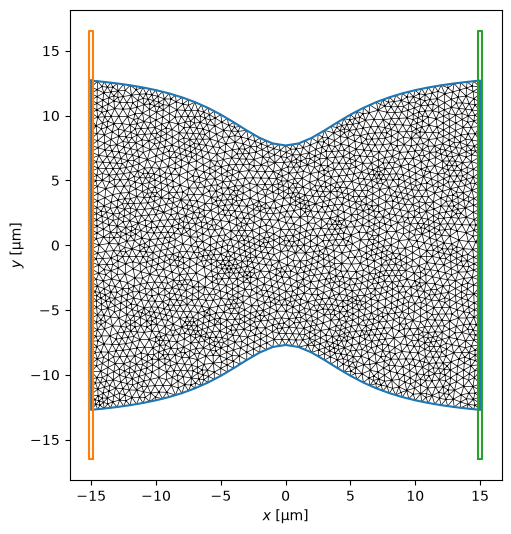

In [11]:
display(device.mesh_stats())
fig, ax = device.plot(mesh=True, legend=False, figsize=(5, 10))

In [12]:
I = J * device.K0.to("uA/um").magnitude * (2*hw[0]) / 4
x0, y0 = 0.0, 0.0
R = 1.5

options = tdgl.SolverOptions(
    skip_time=0,
    solve_time=300,
    output_file="pinning.h5",
    field_units="mT",
    current_units="uA",
    save_every=100,
)

applied_vector_potential = (
    LinearRamp(tmin=0, tmax=100)
    * ConstantField(H * 0.329, field_units=options.field_units,
                    length_units=device.length_units)
)

def eps_pin(r):
    x, y = r
    if (x - x0)**2 + (y - y0)**2 < R**2:
        return -1.0          # normal core (or e.g. 0.0 for weaker pinning)
    return 1.0

sol = tdgl.solve(device, options,
                 terminal_currents=dict(source=I, drain=-I),
                 applied_vector_potential=ConstantField(H, field_units="mT", length_units="um"),
                 disorder_epsilon=eps_pin)

The terminal currents are non-null, but the device has no probe points.
Simulating:   0%|          | 0/300 [00:00<?, ?tau/s ]

Simulating: 100%|█████████▉| 300/300 [00:42<00:00,  7.11tau/s ]


In [13]:
solution = tdgl.Solution.from_hdf5("pinning.h5")

In [14]:
with h5py.File(solution.path, "r") as h5file:
    n = len(h5file["data"].keys())
    anim = create_animation(h5file, quantities=("order_parameter", "phase"),
                            fps=20, min_frame=0, max_frame=n - 1,
                            figure_kwargs=dict(figsize=(10, 5)))
    anim.save("pinning.mp4", writer="ffmpeg", fps=20, dpi=150)
plt.close("all")